In [1]:
# STEP 1 - Convert pdf into separate pages
from langchain_community.document_loaders import PyPDFLoader, TextLoader, WebBaseLoader

#loader = WebBaseLoader("https://en.wikipedia.org/wiki/Climate_change")
#loader = TextLoader("AI.txt")

#loader = PyPDFLoader("Artificial-Intelligence.pdf")
loader = PyPDFLoader("06-LSA Advert October 2026.pdf")

pdf_pages = loader.load()
print(f'No of pages: {len(pdf_pages)}')

C:\Users\User\AppData\Local\Temp\ipykernel_35592\70775724.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader, TextLoader, WebBaseLoader
USER_AGENT environment variable not set, consider setting it to identify your requests.


No of pages: 2


In [2]:
# STEP 2 - Convert every page into sub-pages (chunks)
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(
    chunk_size=300,
    chunk_overlap=50,
           separators=["\n\n", "\n", ",", " "]
)
chunk_documents = splitter.split_documents(pdf_pages);
print(f'No of chunks: {len(chunk_documents)}')

No of chunks: 10


In [3]:
# STEP 3 - Convert every chunk into vectors.
# STEP 4 - Store these vectors into Vector database.
from langchain_ollama import OllamaEmbeddings
from langchain_community.vectorstores import FAISS

embedding_model = OllamaEmbeddings(model="nomic-embed-text")
print('Embedding model is ready')

faiss_vector_store = FAISS. from_documents (chunk_documents, embedding_model)
faiss_vector_store. save_local("11-faiss-ai-book")
print('FAISS Vector store created')

Embedding model is ready
FAISS Vector store created


In [12]:
# STEP 5 - Build Retrieval Chain

from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from langchain_classic.chains import RetrievalQA

model = ChatOllama(model="gpt-oss:120b-cloud")
print( 'Chat Model is ready to use!')

USER_PROMPT_TEMPLATE = """
    Use the following piece of the context to answer user's question.
    If you don't know the answer, just say you don't know, don't try to make the answer.
    Hey can you tell me the school name mentioned in this?
    ---------------------------------
    {context}
    Question: {question}
"""

prompt_template = PromptTemplate(
    template=USER_PROMPT_TEMPLATE,
    input_variables=["context", "question"]
)
retriever = faiss_vector_store.as_retriever()
qa_chain = RetrievalQA.from_chain_type(
    model,
    chain_type="stuff",
    retriever=retriever,
    return_source_documents=True,
    chain_type_kwargs={ "prompt": prompt_template }
)
print('Retrieval chain is ready!!')

Chat Model is ready to use!
Retrieval chain is ready!!


In [5]:
response = qa_chain.invoke("What is the school name for which the job application it is?")
response

{'query': 'What is the school name for which the job application it is?',
 'result': 'The job posting is for **Limington House (Limington House School)**.',
 'source_documents': [Document(id='3eb6a2f4-833c-4c78-82d0-94a25f96724c', metadata={'producer': 'Microsoft® Word LTSC', 'creator': 'Microsoft® Word LTSC', 'creationdate': '2026-09-30T09:34:26+01:00', 'author': 'lcosgro', 'moddate': '2026-09-30T09:34:26+01:00', 'source': '06-LSA Advert October 2026.pdf', 'total_pages': 2, 'page': 1, 'page_label': '2'}, page_content='- or contact the school office on 01256 322148. \n \nVisits to the school are warmly welcomed and encouraged. \n \nWe reserve the right to close a vacancy earlier than the advertised date if we receive applications \nthat meet the criteria. \n \nPlease note that previous applicants need not apply.'),
  Document(id='685961c9-a0ea-4073-ac93-73abc535faf6', metadata={'producer': 'Microsoft® Word LTSC', 'creator': 'Microsoft® Word LTSC', 'creationdate': '2026-09-30T09:34:26+0

In [6]:
response = qa_chain.invoke("Can you let me know closing date fro the application?")
response

{'query': 'Can you let me know closing date fro the application?',
 'result': 'The application closing date is **Friday\u202f23\u202fOctober\u202f2026 at Noon**.',
 'source_documents': [Document(id='3eb6a2f4-833c-4c78-82d0-94a25f96724c', metadata={'producer': 'Microsoft® Word LTSC', 'creator': 'Microsoft® Word LTSC', 'creationdate': '2026-09-30T09:34:26+01:00', 'author': 'lcosgro', 'moddate': '2026-09-30T09:34:26+01:00', 'source': '06-LSA Advert October 2026.pdf', 'total_pages': 2, 'page': 1, 'page_label': '2'}, page_content='- or contact the school office on 01256 322148. \n \nVisits to the school are warmly welcomed and encouraged. \n \nWe reserve the right to close a vacancy earlier than the advertised date if we receive applications \nthat meet the criteria. \n \nPlease note that previous applicants need not apply.'),
  Document(id='620e8b6a-888e-43c8-b3bc-8fe488325592', metadata={'producer': 'Microsoft® Word LTSC', 'creator': 'Microsoft® Word LTSC', 'creationdate': '2026-09-30T09:

In [7]:
response = qa_chain.invoke("Can you tell me no of centuries doen by Sachin Tendulkar")
response

{'query': 'Can you tell me no of centuries doen by Sachin Tendulkar',
 'result': 'I don’t know.',
 'source_documents': [Document(id='96091a62-49f2-46c3-806b-b0f9782a3677', metadata={'producer': 'Microsoft® Word LTSC', 'creator': 'Microsoft® Word LTSC', 'creationdate': '2026-09-30T09:34:26+01:00', 'author': 'lcosgro', 'moddate': '2026-09-30T09:34:26+01:00', 'source': '06-LSA Advert October 2026.pdf', 'total_pages': 2, 'page': 0, 'page_label': '1'}, page_content='• a positive ‘can do’ attitude \n• good communication and interpersonal skills \nRated a good school (OFSTED, April 2025). \n“Pupils’ lives are transformed by attending this school”. \n“Pupils’ engagement and attention in lessons is exemplary”.'),
  Document(id='685961c9-a0ea-4073-ac93-73abc535faf6', metadata={'producer': 'Microsoft® Word LTSC', 'creator': 'Microsoft® Word LTSC', 'creationdate': '2026-09-30T09:34:26+01:00', 'author': 'lcosgro', 'moddate': '2026-09-30T09:34:26+01:00', 'source': '06-LSA Advert October 2026.pdf', '

In [13]:
# STEP-1: Define the state
from typing import List, TypedDict, Annotated
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages
from langchain_core.documents import Document

class RAGState(TypedDict):
    question: str
    documents: List[Document]
    answer: str

print('Graph Rag state is ready .. ')

Graph Rag state is ready .. 


In [20]:
# STEP-2 - Define the nodes
def  retrieve_documents(state: RAGState):
    question = state['question']
    documents = retriever.invoke(question)
    print(f'Retrieved documents: {documents}')
    return { 'documents': documents }

def generate_answer(state: RAGState):
    question = state['question']
    documents = state['documents']
    
    #context = "\n\n".join([doc.page_content for doc in documents])
    #messages = prompt_template.invoke({"context":context, "question":question})
    #response = model.invoke(messages)
    #return {'answer': response.content}
    context = "\n\n".join(
        document.page_content for document in documents
    )
    messages = prompt_template.invoke({
        "context": context,
        "question": question
    })
    print(f'Generated messages: {messages}')
    response = model.invoke(messages)
    print(f'Model response: {response} ')
    return {
        "answer": response.content
    }
    
print('RAG nodes are ready...')


RAG nodes are ready...


Graph is ready ... 


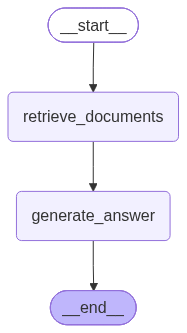

In [21]:
# STEP-3: Add edges and build the graph
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(RAGState)

# Node registration
graph_builder.add_node("retrieve_documents", retrieve_documents)
graph_builder.add_node("generate_answer", generate_answer)

# Add edges
graph_builder.add_edge(START, "retrieve_documents")
graph_builder.add_edge("retrieve_documents", "generate_answer")
graph_builder.add_edge("generate_answer", END)

graph = graph_builder.compile()
print('Graph is ready ... ')
graph

In [22]:
response = graph.invoke({
    "question": "What is school name in the application?"
})
response

Retrieved documents: [Document(id='3eb6a2f4-833c-4c78-82d0-94a25f96724c', metadata={'producer': 'Microsoft® Word LTSC', 'creator': 'Microsoft® Word LTSC', 'creationdate': '2026-09-30T09:34:26+01:00', 'author': 'lcosgro', 'moddate': '2026-09-30T09:34:26+01:00', 'source': '06-LSA Advert October 2026.pdf', 'total_pages': 2, 'page': 1, 'page_label': '2'}, page_content='- or contact the school office on 01256 322148. \n \nVisits to the school are warmly welcomed and encouraged. \n \nWe reserve the right to close a vacancy earlier than the advertised date if we receive applications \nthat meet the criteria. \n \nPlease note that previous applicants need not apply.'), Document(id='685961c9-a0ea-4073-ac93-73abc535faf6', metadata={'producer': 'Microsoft® Word LTSC', 'creator': 'Microsoft® Word LTSC', 'creationdate': '2026-09-30T09:34:26+01:00', 'author': 'lcosgro', 'moddate': '2026-09-30T09:34:26+01:00', 'source': '06-LSA Advert October 2026.pdf', 'total_pages': 2, 'page': 1, 'page_label': '2'}

{'question': 'What is school name in the application?',
 'documents': [Document(id='3eb6a2f4-833c-4c78-82d0-94a25f96724c', metadata={'producer': 'Microsoft® Word LTSC', 'creator': 'Microsoft® Word LTSC', 'creationdate': '2026-09-30T09:34:26+01:00', 'author': 'lcosgro', 'moddate': '2026-09-30T09:34:26+01:00', 'source': '06-LSA Advert October 2026.pdf', 'total_pages': 2, 'page': 1, 'page_label': '2'}, page_content='- or contact the school office on 01256 322148. \n \nVisits to the school are warmly welcomed and encouraged. \n \nWe reserve the right to close a vacancy earlier than the advertised date if we receive applications \nthat meet the criteria. \n \nPlease note that previous applicants need not apply.'),
  Document(id='685961c9-a0ea-4073-ac93-73abc535faf6', metadata={'producer': 'Microsoft® Word LTSC', 'creator': 'Microsoft® Word LTSC', 'creationdate': '2026-09-30T09:34:26+01:00', 'author': 'lcosgro', 'moddate': '2026-09-30T09:34:26+01:00', 'source': '06-LSA Advert October 2026.pd